In [15]:
import os
import gc
import random
import hashlib
import json
import time
import copy
import warnings

from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd

from PIL import Image, ImageFile
from tqdm.auto import tqdm

import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")

In [16]:
SEED = 42

NUM_CLASSES = 18
N_FOLDS = 5

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

ROOT = Path("/kaggle/input/datasets/sweateri/one-piece")

TRAIN_DIR = ROOT / "splitted" / "train"
TEST_DIR = ROOT / "splitted" / "test"

ANNOTATIONS_PATH = ROOT / "train_annotations.csv"
SUBMISSION_PATH = ROOT / "submission.csv"

WORK_DIR = Path("/kaggle/working/one_piece_experiment")
AUDIT_DIR = WORK_DIR / "audit"

META_PATH = WORK_DIR / "clean_metadata.csv"

EXP_DIR = WORK_DIR / "convnext_tiny"
CKPT_DIR = EXP_DIR / "checkpoints"

for path in [
    WORK_DIR,
    AUDIT_DIR,
    EXP_DIR,
    CKPT_DIR
]:
    path.mkdir(parents=True, exist_ok=True)


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything()

print("Python:", __import__("sys").version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu128
CUDA available: True
Device: cuda
GPU: Tesla T4
VRAM: 14.56 GB


In [17]:
assert ROOT.exists(), f"Dataset directory not found: {ROOT}"
assert TRAIN_DIR.exists(), f"Training directory not found: {TRAIN_DIR}"
assert TEST_DIR.exists(), f"Test directory not found: {TEST_DIR}"
assert ANNOTATIONS_PATH.exists(), "Annotations CSV not found"

annotations = pd.read_csv(ANNOTATIONS_PATH)

print("Annotation shape:", annotations.shape)
print("Columns:", annotations.columns.tolist())

display(annotations.head())

print("\nTraining directory:", TRAIN_DIR)
print("Test directory:", TEST_DIR)

Annotation shape: (2916, 6)
Columns: ['id', 'image_name', 'class', 'label', 'split', 'image_path']


,id,image_name,class,label,split,image_path
0,798fbb1a-6b41-4456-aaec-5529552bc2dd,90.png,Rayleigh,12,train,train\Rayleigh\90.png
1,3b137c62-fc85-4cd1-a22b-7d715665bd00,198.jpg,Jinbei,6,train,train\Jinbei\198.jpg
2,de9aca01-b137-44b1-a53e-73e0806ecb4f,78.jpg,Sanji,14,train,train\Sanji\78.jpg
3,affe247e-b769-40dc-8ce8-2ce4e09703d7,192.jpg,Robin,13,train,train\Robin\192.jpg
4,ea7238dc-c470-48ca-958b-7c8268e41667,31.png,Mihawk,10,train,train\Mihawk\31.png



Training directory: /kaggle/input/datasets/sweateri/one-piece/splitted/train
Test directory: /kaggle/input/datasets/sweateri/one-piece/splitted/test


In [18]:
class_to_idx = {
    "Ace": 0,
    "Akainu": 1,
    "Brook": 2,
    "Chopper": 3,
    "Crocodile": 4,
    "Franky": 5,
    "Jinbei": 6,
    "Kurohige": 7,
    "Law": 8,
    "Luffy": 9,
    "Mihawk": 10,
    "Nami": 11,
    "Rayleigh": 12,
    "Robin": 13,
    "Sanji": 14,
    "Shanks": 15,
    "Usopp": 16,
    "Zoro": 17
}

idx_to_class = {
    value: key
    for key, value in class_to_idx.items()
}

assert len(class_to_idx) == NUM_CLASSES
assert len(idx_to_class) == NUM_CLASSES

print("Number of classes:", len(class_to_idx))

display(
    pd.DataFrame({
        "class": list(class_to_idx.keys()),
        "label": list(class_to_idx.values())
    })
)

Number of classes: 18


,class,label
0,Ace,0
1,Akainu,1
2,Brook,2
3,Chopper,3
4,Crocodile,4
5,Franky,5
6,Jinbei,6
7,Kurohige,7
8,Law,8
9,Luffy,9


In [19]:
required_columns = {
    "id",
    "image_name",
    "class",
    "label",
    "split",
    "image_path"
}

assert required_columns.issubset(set(annotations.columns))

print("Number of annotation rows:", len(annotations))
print("Unique classes:", annotations["class"].nunique())
print("Unique filenames:", annotations["image_name"].nunique())

print("\nClass distribution:")
display(
    annotations["class"]
    .value_counts()
    .sort_index()
    .to_frame("images")
)

print("\nLabel consistency:")

for _, row in annotations.iterrows():
    expected_label = class_to_idx[row["class"]]
    assert int(row["label"]) == expected_label

print("All labels match class mapping.")

Number of annotation rows: 2916
Unique classes: 18
Unique filenames: 456

Class distribution:


,images
class,
Ace,168
Akainu,167
Brook,178
Chopper,170
Crocodile,167
Franky,170
Jinbei,167
Kurohige,170
Law,175



Label consistency:
All labels match class mapping.


In [20]:
image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".webp",
    ".bmp"
}

image_index = {}

for p in TRAIN_DIR.rglob("*"):
    if p.is_file() and p.suffix.lower() in image_extensions:
        key = (
            p.parent.name.lower(),
            p.name.lower()
        )

        image_index[key] = str(p)

print("Indexed training images:", len(image_index))

Indexed training images: 2915


In [21]:
meta = pd.DataFrame()

meta["class"] = annotations["class"].astype(str)

meta["label"] = (
    meta["class"]
    .map(class_to_idx)
    .astype(int)
)

meta["image_name"] = (
    annotations["image_name"]
    .astype(str)
)

meta["id"] = (
    annotations["id"]
    .astype(str)
)


resolved_paths = []

for cls, filename in zip(
    meta["class"],
    meta["image_name"]
):
    key = (
        cls.lower(),
        Path(filename).name.lower()
    )

    path = image_index.get(key)

    resolved_paths.append(path)


meta["image_path"] = resolved_paths


missing = meta[meta["image_path"].isna()]

print("Total annotation rows:", len(meta))
print("Resolved images:", meta["image_path"].notna().sum())
print("Missing images:", len(missing))

if len(missing) > 0:
    display(
        missing[
            ["id", "image_name", "class", "label"]
        ].head(20)
    )

    raise ValueError(
        "Some training images could not be resolved."
    )


assert meta["image_path"].map(os.path.isfile).all()
assert len(meta) == len(annotations)
assert meta["label"].between(0, NUM_CLASSES - 1).all()

print("\nAll training image paths successfully resolved!")

display(meta.head())

Total annotation rows: 2916
Resolved images: 2916
Missing images: 0

All training image paths successfully resolved!


,class,label,image_name,id,image_path
0,Rayleigh,12,90.png,798fbb1a-6b41-4456-aaec-5529552bc2dd,/kaggle/input/datasets/sweateri/one-piece/spli...
1,Jinbei,6,198.jpg,3b137c62-fc85-4cd1-a22b-7d715665bd00,/kaggle/input/datasets/sweateri/one-piece/spli...
2,Sanji,14,78.jpg,de9aca01-b137-44b1-a53e-73e0806ecb4f,/kaggle/input/datasets/sweateri/one-piece/spli...
3,Robin,13,192.jpg,affe247e-b769-40dc-8ce8-2ce4e09703d7,/kaggle/input/datasets/sweateri/one-piece/spli...
4,Mihawk,10,31.png,ea7238dc-c470-48ca-958b-7c8268e41667,/kaggle/input/datasets/sweateri/one-piece/spli...


In [22]:
meta.to_csv(META_PATH, index=False)

print("Metadata saved to:", META_PATH)
print("Metadata shape:", meta.shape)

Metadata saved to: /kaggle/working/one_piece_experiment/clean_metadata.csv
Metadata shape: (2916, 5)


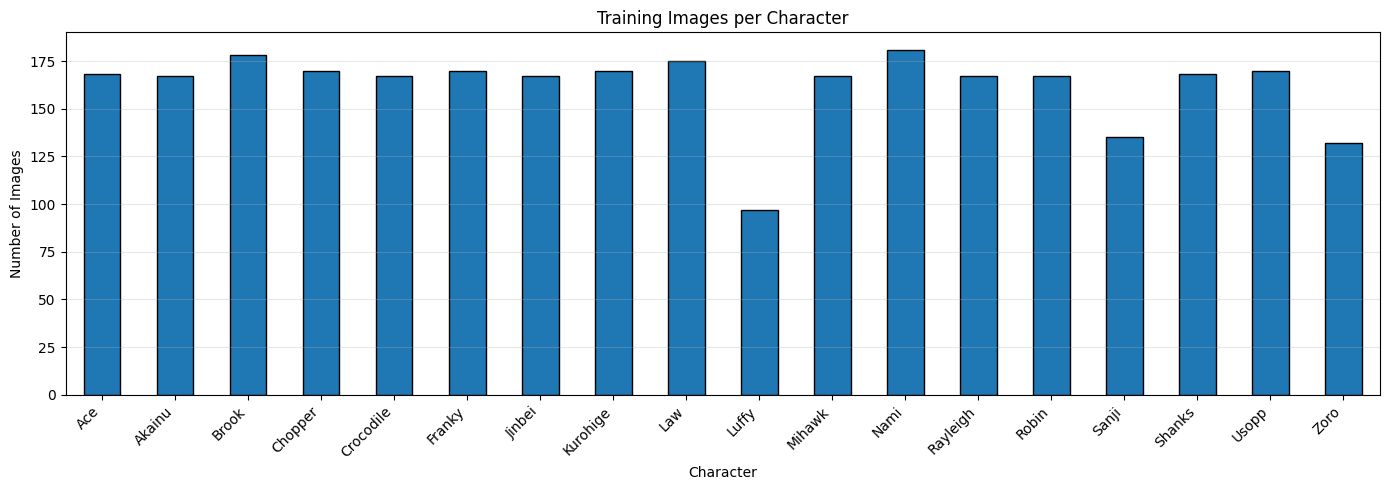

Minimum class size: 97
Maximum class size: 181
Total images: 2916


In [23]:
class_counts = (
    meta["class"]
    .value_counts()
    .reindex(class_to_idx.keys())
)

plt.figure(figsize=(14, 5))

class_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Training Images per Character")
plt.xlabel("Character")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Minimum class size:", class_counts.min())
print("Maximum class size:", class_counts.max())
print("Total images:", class_counts.sum())

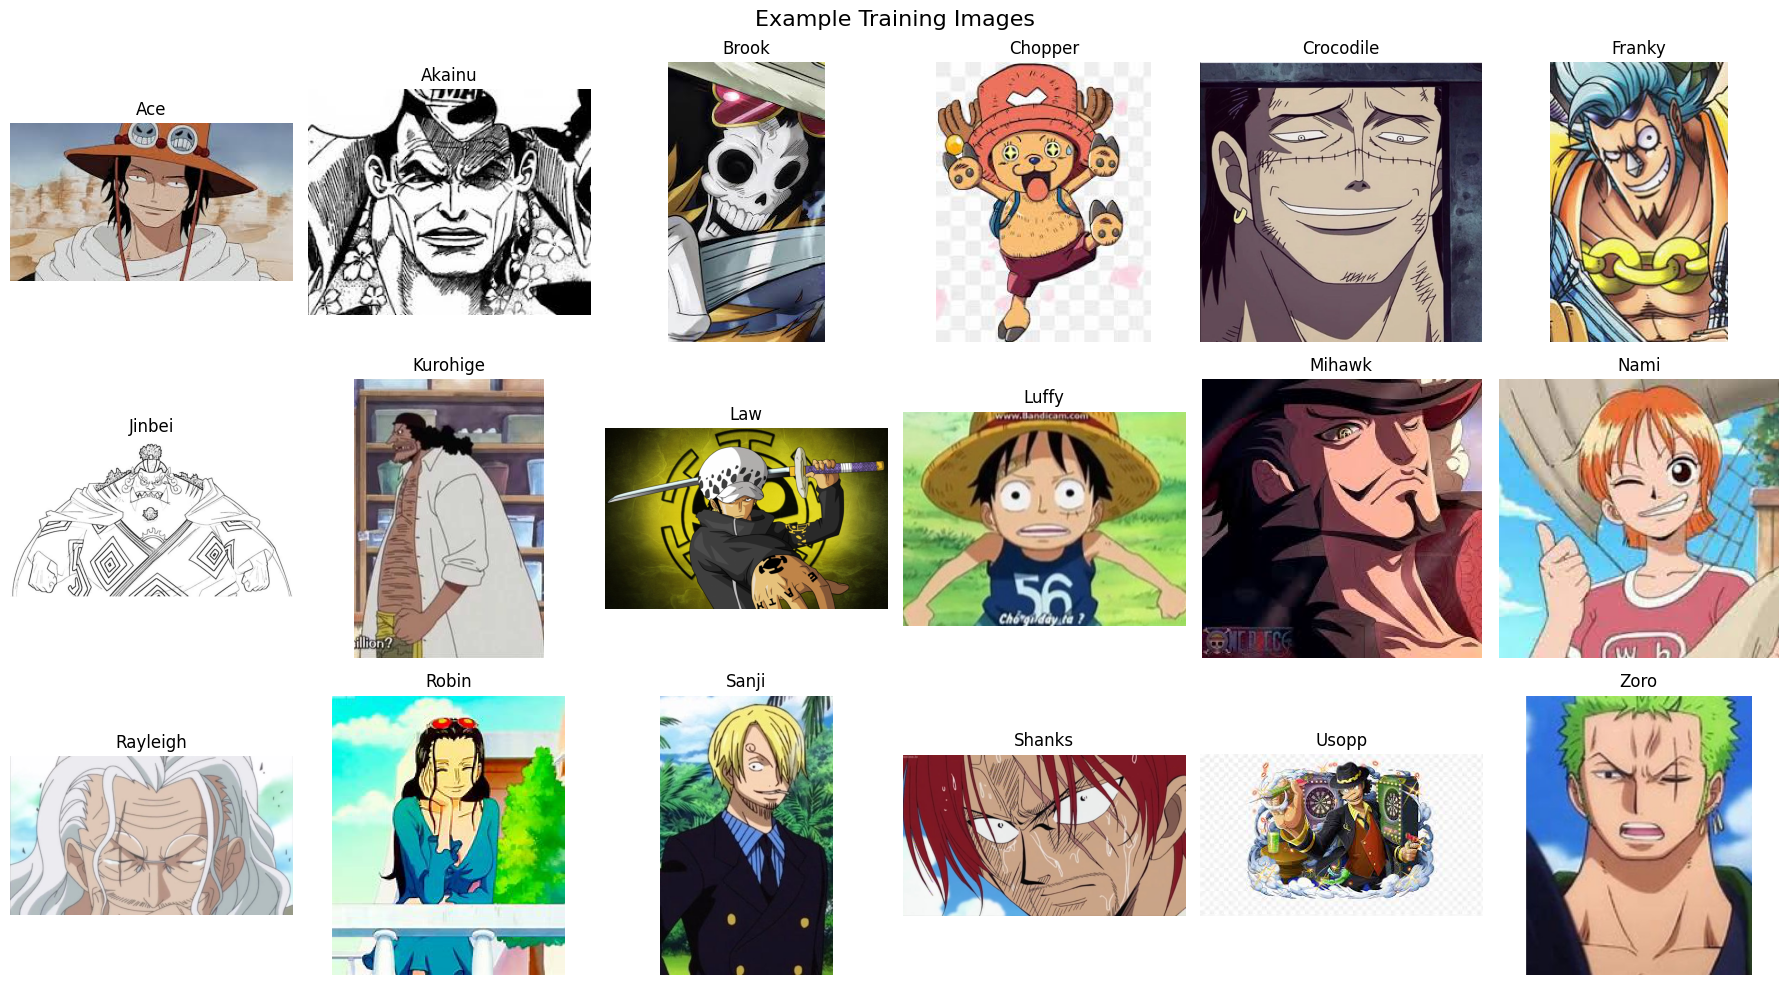

In [24]:
fig, axes = plt.subplots(
    3,
    6,
    figsize=(18, 10)
)

sample_classes = list(class_to_idx.keys())

for ax, cls in zip(axes.flat, sample_classes):
    sample = meta[meta["class"] == cls].sample(
        1,
        random_state=SEED
    ).iloc[0]

    img = Image.open(sample["image_path"]).convert("RGB")

    ax.imshow(img)
    ax.set_title(cls)
    ax.axis("off")

plt.suptitle("Example Training Images", fontsize=16)
plt.tight_layout()
plt.show()

In [25]:
skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED
)

meta["fold"] = -1

for fold, (_, val_idx) in enumerate(
    skf.split(meta, meta["label"])
):
    meta.loc[val_idx, "fold"] = fold

print(meta["fold"].value_counts().sort_index())

fold_distribution = pd.crosstab(
    meta["fold"],
    meta["class"]
)

display(fold_distribution)

assert (meta["fold"] >= 0).all()

meta.to_csv(META_PATH, index=False)

fold
0    584
1    583
2    583
3    583
4    583
Name: count, dtype: int64


class,Ace,Akainu,Brook,Chopper,Crocodile,Franky,Jinbei,Kurohige,Law,Luffy,Mihawk,Nami,Rayleigh,Robin,Sanji,Shanks,Usopp,Zoro
fold,,,,,,,,,,,,,,,,,,
0,34,33,36,34,33,34,33,34,35,19,33,37,34,34,27,34,34,26
1,33,33,36,34,33,34,33,34,35,20,34,36,34,33,27,33,34,27
2,33,33,36,34,33,34,34,34,35,20,34,36,33,33,27,33,34,27
3,34,34,35,34,34,34,34,34,35,19,33,36,33,33,27,34,34,26
4,34,34,35,34,34,34,33,34,35,19,33,36,33,34,27,34,34,26


In [26]:
def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


hashes = []

for path in tqdm(meta["image_path"], desc="Hashing train images"):
    hashes.append(sha256_file(path))

meta["sha256"] = hashes

duplicate_rows = meta[
    meta.duplicated("sha256", keep=False)
].sort_values("sha256")

print("Training rows:", len(meta))
print("Unique SHA256 hashes:", meta["sha256"].nunique())
print("Duplicate rows:", len(duplicate_rows))

if len(duplicate_rows):
    display(
        duplicate_rows[
            ["image_path", "class", "label", "sha256"]
        ].head(30)
    )

duplicate_rows.to_csv(
    AUDIT_DIR / "train_exact_duplicates.csv",
    index=False
)

Hashing train images:   0%|          | 0/2916 [00:00<?, ?it/s]

Training rows: 2916
Unique SHA256 hashes: 2898
Duplicate rows: 36


,image_path,class,label,sha256
665,/kaggle/input/datasets/sweateri/one-piece/spli...,Franky,5,0333f47c3013fd71d57436a4bc9b2db2106043eb093060...
1865,/kaggle/input/datasets/sweateri/one-piece/spli...,Franky,5,0333f47c3013fd71d57436a4bc9b2db2106043eb093060...
310,/kaggle/input/datasets/sweateri/one-piece/spli...,Chopper,3,09b06af145fc6af4fa90069d03ac5e5f7ddbffc0e5e68c...
2186,/kaggle/input/datasets/sweateri/one-piece/spli...,Chopper,3,09b06af145fc6af4fa90069d03ac5e5f7ddbffc0e5e68c...
2311,/kaggle/input/datasets/sweateri/one-piece/spli...,Franky,5,1c867731450c55705f20acf8c4dad1a8e9b2226e1aced4...
1774,/kaggle/input/datasets/sweateri/one-piece/spli...,Franky,5,1c867731450c55705f20acf8c4dad1a8e9b2226e1aced4...
882,/kaggle/input/datasets/sweateri/one-piece/spli...,Nami,11,29bc08ed91aefd5b65fe2b6022921463d03c41600a14c5...
1039,/kaggle/input/datasets/sweateri/one-piece/spli...,Nami,11,29bc08ed91aefd5b65fe2b6022921463d03c41600a14c5...
59,/kaggle/input/datasets/sweateri/one-piece/spli...,Franky,5,47cccbe1af02190c9e7cb755a632442c32b279218513d7...
2717,/kaggle/input/datasets/sweateri/one-piece/spli...,Franky,5,47cccbe1af02190c9e7cb755a632442c32b279218513d7...


In [28]:
test_files = [
    p for p in TEST_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

test_hashes = {}

for path in tqdm(test_files, desc="Hashing test images"):
    test_hashes[str(path)] = sha256_file(path)

train_hash_to_rows = defaultdict(list)

for _, row in meta.iterrows():
    train_hash_to_rows[row["sha256"]].append(row)

exact_matches = []

for test_path, test_hash in test_hashes.items():
    if test_hash in train_hash_to_rows:
        for train_row in train_hash_to_rows[test_hash]:
            exact_matches.append({
                "test_path": test_path,
                "train_path": train_row["image_path"],
                "train_class": train_row["class"],
                "train_label": train_row["label"],
                "sha256": test_hash
            })

exact_matches = pd.DataFrame(exact_matches)

print("Test images:", len(test_files))
print("Exact train-test matches:", len(exact_matches))

display(exact_matches.head(20))

exact_matches.to_csv(
    AUDIT_DIR / "train_test_exact_duplicates.csv",
    index=False
)

Hashing test images:   0%|          | 0/849 [00:00<?, ?it/s]

Test images: 849
Exact train-test matches: 10


,test_path,train_path,train_class,train_label,sha256
0,/kaggle/input/datasets/sweateri/one-piece/spli...,/kaggle/input/datasets/sweateri/one-piece/spli...,Brook,2,529dceed035fe82bd4ea1b6c6784c644afd668c21aa66b...
1,/kaggle/input/datasets/sweateri/one-piece/spli...,/kaggle/input/datasets/sweateri/one-piece/spli...,Nami,11,451a4192695c8ab183a407ebf1cd865cd3fb6d91c99d8f...
2,/kaggle/input/datasets/sweateri/one-piece/spli...,/kaggle/input/datasets/sweateri/one-piece/spli...,Franky,5,2f6bbc41f167b49b1c42b5253eb8e6a41229a6a2e2efd1...
3,/kaggle/input/datasets/sweateri/one-piece/spli...,/kaggle/input/datasets/sweateri/one-piece/spli...,Usopp,16,7fbe822285574d5ba200942323edec1c18868269c0f1e0...
4,/kaggle/input/datasets/sweateri/one-piece/spli...,/kaggle/input/datasets/sweateri/one-piece/spli...,Franky,5,6fac6757cbd1a137fb745d0e1886d26909cbb8d9d4f2de...
5,/kaggle/input/datasets/sweateri/one-piece/spli...,/kaggle/input/datasets/sweateri/one-piece/spli...,Franky,5,7b5d7f4aa68035407a6593319b2314a189250487533c88...
6,/kaggle/input/datasets/sweateri/one-piece/spli...,/kaggle/input/datasets/sweateri/one-piece/spli...,Franky,5,e6428f3e3975dc1f4bede5c1fd44f66848e29bd20461f0...
7,/kaggle/input/datasets/sweateri/one-piece/spli...,/kaggle/input/datasets/sweateri/one-piece/spli...,Brook,2,d3aa08862958a5009d642fd63017cd464587e98b851e4e...
8,/kaggle/input/datasets/sweateri/one-piece/spli...,/kaggle/input/datasets/sweateri/one-piece/spli...,Franky,5,1a827f9c5ca3a5835f8610a74cd46f98e2aadf9e190e8a...
9,/kaggle/input/datasets/sweateri/one-piece/spli...,/kaggle/input/datasets/sweateri/one-piece/spli...,Sanji,14,5e125cd48a7909d78ee50d4a44dae24e0d65c11d0936c9...


In [29]:
from PIL import ImageOps

IMAGE_SIZE = 320

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


class Letterbox:
    def __init__(self, size, fill=(0, 0, 0)):
        self.size = size
        self.fill = fill

    def __call__(self, image):
        image = image.convert("RGB")

        image.thumbnail(
            (self.size, self.size),
            Image.Resampling.BICUBIC
        )

        canvas = Image.new(
            "RGB",
            (self.size, self.size),
            self.fill
        )

        x = (self.size - image.width) // 2
        y = (self.size - image.height) // 2

        canvas.paste(image, (x, y))

        return canvas


train_transform = transforms.Compose([
    Letterbox(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.10,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])

valid_transform = transforms.Compose([
    Letterbox(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])

test_transform = valid_transform

In [30]:
class OnePieceDataset(Dataset):
    def __init__(
        self,
        dataframe,
        transform=None,
        test_mode=False
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.test_mode = test_mode

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = row["image_path"]

        image = Image.open(image_path).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        if self.test_mode:
            return image

        label = int(row["label"])

        return image, label

In [31]:
def build_model(num_classes=NUM_CLASSES, pretrained=True):
    weights = (
        models.ConvNeXt_Tiny_Weights.DEFAULT
        if pretrained
        else None
    )

    model = models.convnext_tiny(weights=weights)

    in_features = model.classifier[2].in_features

    model.classifier[2] = nn.Linear(
        in_features,
        num_classes
    )

    return model


model = build_model(pretrained=True)

print(model.classifier)
print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)

del model
gc.collect()
torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 180MB/s] 


Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=18, bias=True)
)
Parameters: 27833970


In [32]:
EPOCHS = 20
BATCH_SIZE = 16

BACKBONE_LR = 2e-5
HEAD_LR = 3e-4

WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.05

NUM_WORKERS = 2

USE_AMP = DEVICE.type == "cuda"

RUN_TRAINING = True

print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Backbone LR:", BACKBONE_LR)
print("Head LR:", HEAD_LR)
print("Mixed precision:", USE_AMP)

Epochs: 20
Batch size: 16
Backbone LR: 2e-05
Head LR: 0.0003
Mixed precision: True


In [33]:
def create_optimizer(model):
    head_params = list(model.classifier.parameters())

    head_ids = {
        id(p) for p in head_params
    }

    backbone_params = [
        p for p in model.parameters()
        if id(p) not in head_ids
    ]

    optimizer = torch.optim.AdamW(
        [
            {
                "params": backbone_params,
                "lr": BACKBONE_LR
            },
            {
                "params": head_params,
                "lr": HEAD_LR
            }
        ],
        weight_decay=WEIGHT_DECAY
    )

    return optimizer


def run_train_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler
):
    model.train()

    total_loss = 0
    all_targets = []
    all_predictions = []

    for images, targets in tqdm(
        loader,
        desc="Training",
        leave=False
    ):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):
            logits = model(images)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

        predictions = logits.argmax(dim=1)

        all_targets.extend(targets.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(
        all_targets,
        all_predictions
    )

    macro_f1 = f1_score(
        all_targets,
        all_predictions,
        average="macro"
    )

    return avg_loss, accuracy, macro_f1


@torch.no_grad()
def run_valid_epoch(model, loader, criterion):
    model.eval()

    total_loss = 0
    all_targets = []
    all_predictions = []

    for images, targets in tqdm(
        loader,
        desc="Validation",
        leave=False
    ):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):
            logits = model(images)
            loss = criterion(logits, targets)

        total_loss += loss.item() * images.size(0)

        predictions = logits.argmax(dim=1)

        all_targets.extend(targets.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(
        all_targets,
        all_predictions
    )

    macro_f1 = f1_score(
        all_targets,
        all_predictions,
        average="macro"
    )

    return (
        avg_loss,
        accuracy,
        macro_f1,
        np.array(all_targets),
        np.array(all_predictions)
    )

In [34]:
def train_one_fold(fold):
    print(f"\n{'=' * 60}")
    print(f"FOLD {fold + 1}/{N_FOLDS}")
    print(f"{'=' * 60}")

    train_df = meta[meta["fold"] != fold].copy()
    valid_df = meta[meta["fold"] == fold].copy()

    train_dataset = OnePieceDataset(
        train_df,
        transform=train_transform
    )

    valid_dataset = OnePieceDataset(
        valid_df,
        transform=valid_transform
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=BATCH_SIZE * 2,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP
    )

    model = build_model(pretrained=True).to(DEVICE)

    optimizer = create_optimizer(model)

    criterion = nn.CrossEntropyLoss(
        label_smoothing=LABEL_SMOOTHING
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    best_f1 = -1
    best_epoch = 0

    history = []

    def lr_lambda(epoch):
        warmup_epochs = 2

        if epoch < warmup_epochs:
            return (epoch + 1) / warmup_epochs

        progress = (
            epoch - warmup_epochs
        ) / max(1, EPOCHS - warmup_epochs)

        return 0.5 * (1 + np.cos(np.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda=lr_lambda
    )

    checkpoint_path = (
        CKPT_DIR / f"convnext_tiny_fold{fold}.pth"
    )

    for epoch in range(EPOCHS):
        start_time = time.time()

        train_loss, train_acc, train_f1 = run_train_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            scaler
        )

        (
            valid_loss,
            valid_acc,
            valid_f1,
            valid_targets,
            valid_predictions
        ) = run_valid_epoch(
            model,
            valid_loader,
            criterion
        )

        scheduler.step()

        elapsed = time.time() - start_time

        history.append({
            "fold": fold,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_macro_f1": train_f1,
            "valid_loss": valid_loss,
            "valid_accuracy": valid_acc,
            "valid_macro_f1": valid_f1,
            "seconds": elapsed
        })

        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train F1: {train_f1:.4f} | "
            f"Valid loss: {valid_loss:.4f} | "
            f"Valid F1: {valid_f1:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

        if valid_f1 > best_f1:
            best_f1 = valid_f1
            best_epoch = epoch + 1

            torch.save(
                {
                    "fold": fold,
                    "epoch": best_epoch,
                    "model_state_dict": model.state_dict(),
                    "valid_macro_f1": best_f1,
                    "class_to_idx": class_to_idx
                },
                checkpoint_path
            )

    print(
        f"Best fold {fold} F1: {best_f1:.5f} "
        f"at epoch {best_epoch}"
    )

    del model
    del optimizer
    del train_loader
    del valid_loader

    gc.collect()
    torch.cuda.empty_cache()

    return pd.DataFrame(history)

In [ ]:
all_histories = []

if RUN_TRAINING:
    for fold in range(N_FOLDS):
        history = train_one_fold(fold)
        all_histories.append(history)

    training_history = pd.concat(
        all_histories,
        ignore_index=True
    )

    training_history.to_csv(
        EXP_DIR / "training_history.csv",
        index=False
    )

    print("Training completed.")
else:
    print("Training skipped. Existing checkpoints will be used.")

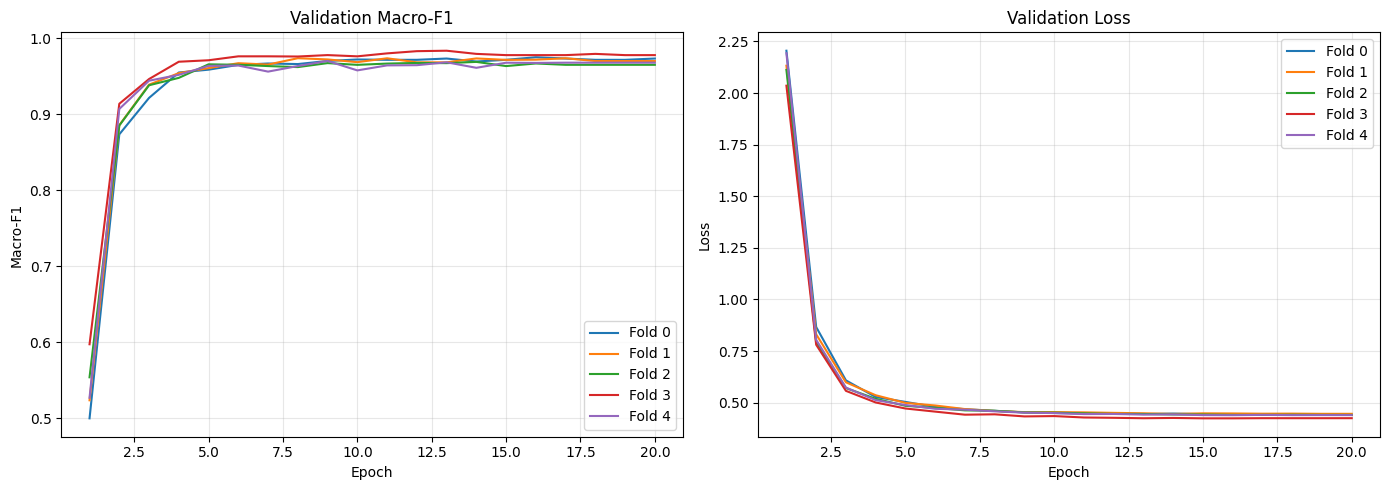

In [38]:
history_path = EXP_DIR / "training_history.csv"

if history_path.exists():
    training_history = pd.read_csv(history_path)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for fold in sorted(training_history["fold"].unique()):
        fold_history = training_history[
            training_history["fold"] == fold
        ]

        axes[0].plot(
            fold_history["epoch"],
            fold_history["valid_macro_f1"],
            label=f"Fold {fold}"
        )

        axes[1].plot(
            fold_history["epoch"],
            fold_history["valid_loss"],
            label=f"Fold {fold}"
        )

    axes[0].set_title("Validation Macro-F1")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Macro-F1")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].set_title("Validation Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()
else:
    print("Training history not found.")

In [41]:
@torch.no_grad()
def predict_with_tta(model, loader):
    model.eval()

    all_probabilities = []

    for images in tqdm(loader, desc="Predicting", leave=False):
        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):
            logits_original = model(images)
            logits_flipped = model(torch.flip(images, dims=[3]))

            probs_original = torch.softmax(
                logits_original.float(),
                dim=1
            )

            probs_flipped = torch.softmax(
                logits_flipped.float(),
                dim=1
            )

            probabilities = (
                probs_original + probs_flipped
            ) / 2

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

    return np.concatenate(all_probabilities, axis=0)


test_dataset = OnePieceDataset(
    test_df,
    transform=test_transform,
    test_mode=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE * 2,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=USE_AMP
)

print("Test loader batches:", len(test_loader))

Test loader batches: 27


In [42]:
fold_probabilities = []

for fold in range(N_FOLDS):
    checkpoint_path = (
        CKPT_DIR / f"convnext_tiny_fold{fold}.pth"
    )

    assert checkpoint_path.exists(), (
        f"Checkpoint not found: {checkpoint_path}"
    )

    model = build_model(pretrained=False).to(DEVICE)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    probabilities = predict_with_tta(
        model,
        test_loader
    )

    fold_probabilities.append(probabilities)

    print(
        f"Fold {fold}: "
        f"prediction shape = {probabilities.shape}"
    )

    del model
    del checkpoint

    gc.collect()
    torch.cuda.empty_cache()


test_probabilities = np.mean(
    fold_probabilities,
    axis=0
)

print("Ensemble prediction shape:", test_probabilities.shape)

assert test_probabilities.shape == (
    len(test_df),
    NUM_CLASSES
)

assert np.isfinite(test_probabilities).all()

Predicting:   0%|          | 0/27 [00:00<?, ?it/s]

Fold 0: prediction shape = (849, 18)


Predicting:   0%|          | 0/27 [00:00<?, ?it/s]

Fold 1: prediction shape = (849, 18)


Predicting:   0%|          | 0/27 [00:00<?, ?it/s]

Fold 2: prediction shape = (849, 18)


Predicting:   0%|          | 0/27 [00:00<?, ?it/s]

Fold 3: prediction shape = (849, 18)


Predicting:   0%|          | 0/27 [00:00<?, ?it/s]

Fold 4: prediction shape = (849, 18)
Ensemble prediction shape: (849, 18)


In [43]:
test_predictions = test_probabilities.argmax(axis=1)

test_df["predicted_label"] = test_predictions
test_df["predicted_class"] = (
    test_df["predicted_label"].map(idx_to_class)
)

display(
    test_df[
        ["id", "image_name", "predicted_class", "predicted_label"]
    ].head(20)
)

print("Predictions:", len(test_predictions))
print("Predicted classes:", pd.Series(test_predictions).nunique())

,id,image_name,predicted_class,predicted_label
0,002999fb-803d-45b2-b647-6203e446e475,002999fb-803d-45b2-b647-6203e446e475.png,Brook,2
1,00479183-ca4e-49c1-927d-f7209ff23145,00479183-ca4e-49c1-927d-f7209ff23145.png,Nami,11
2,0048719e-24d9-4a5a-af75-ca62c2e90477,0048719e-24d9-4a5a-af75-ca62c2e90477.png,Law,8
3,00c99fe0-e1c9-48ef-8d16-1ea380f190cd,00c99fe0-e1c9-48ef-8d16-1ea380f190cd.png,Jinbei,6
4,00efbf59-d4c4-4d7e-8bc6-86af36367515,00efbf59-d4c4-4d7e-8bc6-86af36367515.png,Mihawk,10
5,01466536-a300-4853-9858-fcd909464b5f,01466536-a300-4853-9858-fcd909464b5f.png,Kurohige,7
6,0150c7db-e962-4570-8072-c78d774639f8,0150c7db-e962-4570-8072-c78d774639f8.jpg,Jinbei,6
7,01f5ceb8-4180-4e39-8a8c-7c46cb75ab33,01f5ceb8-4180-4e39-8a8c-7c46cb75ab33.png,Chopper,3
8,021185cc-ccd9-4fb3-b797-d1922042ac4d,021185cc-ccd9-4fb3-b797-d1922042ac4d.png,Chopper,3
9,02e4921e-4770-4e4d-86d6-a6b3fcd2f399,02e4921e-4770-4e4d-86d6-a6b3fcd2f399.jpg,Luffy,9


Predictions: 849
Predicted classes: 18


In [44]:
confirmed_path = (
    AUDIT_DIR / "confirmed_duplicate_predictions.csv"
)

test_df["final_label"] = test_df["predicted_label"].astype(int)

if confirmed_path.exists():
    confirmed = pd.read_csv(confirmed_path)

    required = {
        "test_id",
        "nearest_train_class"
    }

    if required.issubset(confirmed.columns):
        duplicate_mapping = (
            confirmed
            .drop_duplicates("test_id")
            .set_index("test_id")["nearest_train_class"]
            .to_dict()
        )

        corrections = 0

        for index, row in test_df.iterrows():
            test_id = str(row["id"])

            if test_id in duplicate_mapping:
                class_name = duplicate_mapping[test_id]

                if class_name not in class_to_idx:
                    raise ValueError(
                        f"Unknown class in duplicate file: {class_name}"
                    )

                test_df.at[index, "final_label"] = (
                    class_to_idx[class_name]
                )

                corrections += 1

        print("Applied confirmed duplicate corrections:", corrections)

    else:
        print(
            "Duplicate file exists but required columns are missing. "
            "No corrections applied."
        )

else:
    print(
        "No confirmed duplicate file found. "
        "Using model predictions without duplicate corrections."
    )

test_df["final_class"] = (
    test_df["final_label"].map(idx_to_class)
)

display(
    test_df[
        ["id", "predicted_class", "final_class"]
    ].head(20)
)

No confirmed duplicate file found. Using model predictions without duplicate corrections.


,id,predicted_class,final_class
0,002999fb-803d-45b2-b647-6203e446e475,Brook,Brook
1,00479183-ca4e-49c1-927d-f7209ff23145,Nami,Nami
2,0048719e-24d9-4a5a-af75-ca62c2e90477,Law,Law
3,00c99fe0-e1c9-48ef-8d16-1ea380f190cd,Jinbei,Jinbei
4,00efbf59-d4c4-4d7e-8bc6-86af36367515,Mihawk,Mihawk
5,01466536-a300-4853-9858-fcd909464b5f,Kurohige,Kurohige
6,0150c7db-e962-4570-8072-c78d774639f8,Jinbei,Jinbei
7,01f5ceb8-4180-4e39-8a8c-7c46cb75ab33,Chopper,Chopper
8,021185cc-ccd9-4fb3-b797-d1922042ac4d,Chopper,Chopper
9,02e4921e-4770-4e4d-86d6-a6b3fcd2f399,Luffy,Luffy


In [45]:
submission = pd.read_csv(SUBMISSION_PATH)

print("Submission shape:", submission.shape)
print("Submission columns:", submission.columns.tolist())

display(submission.head())

assert len(submission) == len(test_df), (
    "Submission template and test dataset have different sizes."
)

Submission shape: (849, 2)
Submission columns: ['id', 'label']


,id,label
0,c41628b1-4781-4392-ac8d-6bfe981f73f9,0
1,f114acb3-fe18-478b-a19a-1f4cbe098851,0
2,d952ecfe-750c-44b2-96c2-1cac1a4ee146,0
3,2c14ec77-44ca-4b3c-b470-96286411c617,0
4,712c3ce9-750a-4cc4-8f94-f8033c31cb2c,0


In [46]:
prediction_mapping = dict(
    zip(
        test_df["id"].astype(str),
        test_df["final_class"].astype(str)
    )
)

assert "id" in submission.columns, (
    "The submission template must contain an id column."
)

submission_ids = submission["id"].astype(str)

missing_ids = [
    image_id
    for image_id in submission_ids
    if image_id not in prediction_mapping
]

print("IDs missing from predictions:", len(missing_ids))

if missing_ids:
    print("Examples:", missing_ids[:10])
    raise ValueError(
        "Some submission IDs do not match test image IDs."
    )

candidate_target_columns = [
    "class",
    "character",
    "label",
    "target"
]

target_columns = [
    col for col in candidate_target_columns
    if col in submission.columns
]

if len(target_columns) != 1:
    raise ValueError(
        "Could not uniquely identify the target column. "
        f"Submission columns: {submission.columns.tolist()}. "
        "Set TARGET_COL manually."
    )

TARGET_COL = target_columns[0]

submission[TARGET_COL] = submission_ids.map(
    prediction_mapping
)

assert submission[TARGET_COL].notna().all()

display(submission.head(10))
print("Target column:", TARGET_COL)

IDs missing from predictions: 0


,id,label
0,c41628b1-4781-4392-ac8d-6bfe981f73f9,Mihawk
1,f114acb3-fe18-478b-a19a-1f4cbe098851,Kurohige
2,d952ecfe-750c-44b2-96c2-1cac1a4ee146,Brook
3,2c14ec77-44ca-4b3c-b470-96286411c617,Sanji
4,712c3ce9-750a-4cc4-8f94-f8033c31cb2c,Ace
5,ea7f009d-d2b5-45d8-ac9a-3c1ec20e0d72,Akainu
6,6106910d-5295-474a-b12b-1321f0dc7684,Shanks
7,b80535cd-e94f-4732-a7d9-93f3a1723711,Franky
8,01f5ceb8-4180-4e39-8a8c-7c46cb75ab33,Chopper
9,a896665e-1e2d-4594-a256-c715cea0883a,Mihawk


Target column: label


In [47]:
OUTPUT_SUBMISSION = (
    WORK_DIR / "submission_final.csv"
)

assert len(submission) == 849, (
    f"Expected 849 rows, got {len(submission)}"
)

assert submission["id"].is_unique
assert submission[TARGET_COL].isin(class_to_idx.keys()).all()

submission.to_csv(
    OUTPUT_SUBMISSION,
    index=False
)

print("Submission saved:", OUTPUT_SUBMISSION)
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())

display(submission.head())

Submission saved: /kaggle/working/one_piece_experiment/submission_final.csv
Rows: 849
Columns: ['id', 'label']


,id,label
0,c41628b1-4781-4392-ac8d-6bfe981f73f9,Mihawk
1,f114acb3-fe18-478b-a19a-1f4cbe098851,Kurohige
2,d952ecfe-750c-44b2-96c2-1cac1a4ee146,Brook
3,2c14ec77-44ca-4b3c-b470-96286411c617,Sanji
4,712c3ce9-750a-4cc4-8f94-f8033c31cb2c,Ace


In [48]:
fold_metrics = []
oof_predictions = np.full(len(meta), -1, dtype=np.int64)

for fold in range(N_FOLDS):
    checkpoint_path = (
        CKPT_DIR / f"convnext_tiny_fold{fold}.pth"
    )

    assert checkpoint_path.exists(), (
        f"Missing checkpoint: {checkpoint_path}"
    )

    valid_df = meta[
        meta["fold"] == fold
    ].copy()

    valid_dataset = OnePieceDataset(
        valid_df,
        transform=valid_transform
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=BATCH_SIZE * 2,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP
    )

    model = build_model(pretrained=False).to(DEVICE)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    _, accuracy, macro_f1, targets, predictions = (
        run_valid_epoch(
            model,
            valid_loader,
            nn.CrossEntropyLoss()
        )
    )

    oof_predictions[valid_df.index.to_numpy()] = predictions

    fold_metrics.append({
        "fold": fold,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "samples": len(valid_df)
    })

    print(
        f"Fold {fold}: "
        f"Accuracy={accuracy:.5f}, "
        f"Macro-F1={macro_f1:.5f}"
    )

    del model, checkpoint, valid_loader, valid_dataset
    gc.collect()
    torch.cuda.empty_cache()


fold_metrics = pd.DataFrame(fold_metrics)

display(fold_metrics)

assert (oof_predictions >= 0).all()

print("\nMean CV accuracy:", fold_metrics["accuracy"].mean())
print("Mean CV macro-F1:", fold_metrics["macro_f1"].mean())

print(
    "OOF accuracy:",
    accuracy_score(meta["label"], oof_predictions)
)

print(
    "OOF macro-F1:",
    f1_score(
        meta["label"],
        oof_predictions,
        average="macro"
    )
)

fold_metrics.to_csv(
    EXP_DIR / "fold_metrics.csv",
    index=False
)

np.save(
    EXP_DIR / "oof_predictions.npy",
    oof_predictions
)

Validation:   0%|          | 0/19 [00:00<?, ?it/s]

Fold 0: Accuracy=0.97603, Macro-F1=0.97515


Validation:   0%|          | 0/19 [00:00<?, ?it/s]

Fold 1: Accuracy=0.97427, Macro-F1=0.97387


Validation:   0%|          | 0/19 [00:00<?, ?it/s]

Fold 2: Accuracy=0.96913, Macro-F1=0.96904


... (2 outputs left out)

Validation:   0%|          | 0/19 [00:00<?, ?it/s]

Fold 4: Accuracy=0.97256, Macro-F1=0.97022


,fold,accuracy,macro_f1,samples
0,0,0.976027,0.975155,584
1,1,0.974271,0.973867,583
2,2,0.969125,0.969037,583
3,3,0.982847,0.983745,583
4,4,0.972556,0.970219,583



Mean CV accuracy: 0.9749653422307855
Mean CV macro-F1: 0.9744046845077008
OOF accuracy: 0.9749657064471879
OOF macro-F1: 0.9744381337162227


In [49]:
print(
    classification_report(
        meta["label"],
        oof_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=[
            idx_to_class[i]
            for i in range(NUM_CLASSES)
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Ace       0.95      0.95      0.95       168
      Akainu       0.98      0.98      0.98       167
       Brook       0.97      0.98      0.97       178
     Chopper       0.99      0.99      0.99       170
   Crocodile       0.99      0.97      0.98       167
      Franky       0.97      0.98      0.97       170
      Jinbei       0.99      0.99      0.99       167
    Kurohige       0.98      0.96      0.97       170
         Law       0.99      0.97      0.98       175
       Luffy       0.96      0.94      0.95        97
      Mihawk       0.97      0.99      0.98       167
        Nami       0.98      0.99      0.99       181
    Rayleigh       0.97      0.99      0.98       167
       Robin       0.96      0.99      0.98       167
       Sanji       0.99      0.98      0.99       135
      Shanks       0.97      0.93      0.95       168
       Usopp       0.95      0.96      0.96       170
        Zoro       0.98    

In [50]:
model_for_report = build_model(pretrained=False)

total_parameters = sum(
    p.numel()
    for p in model_for_report.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model_for_report.parameters()
    if p.requires_grad
)

del model_for_report

checkpoint_report = []

for path in sorted(CKPT_DIR.glob("convnext_tiny_fold*.pth")):
    checkpoint_report.append({
        "checkpoint": path.name,
        "size_mb": path.stat().st_size / 1024**2
    })

checkpoint_report = pd.DataFrame(checkpoint_report)

display(checkpoint_report)

total_checkpoint_size = checkpoint_report["size_mb"].sum()

print("Architecture: ConvNeXt-Tiny")
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Total checkpoint size: {total_checkpoint_size:.2f} MB")
print(
    "Average checkpoint size:",
    f"{checkpoint_report['size_mb'].mean():.2f} MB"
)

,checkpoint,size_mb
0,convnext_tiny_fold0.pth,106.244357
1,convnext_tiny_fold1.pth,106.244357
2,convnext_tiny_fold2.pth,106.244357
3,convnext_tiny_fold3.pth,106.244357
4,convnext_tiny_fold4.pth,106.244357


Architecture: ConvNeXt-Tiny
Total parameters: 27,833,970
Trainable parameters: 27,833,970
Total checkpoint size: 531.22 MB
Average checkpoint size: 106.24 MB
